[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch08-simple_workbook.ipynb)

# Every pair of words in Pride and Prejudice

A recurrent encoder reads a chapter one word after another; self-attention
scores every pair of its words in one product. How many steps in order, and
how many scores, does each chapter of the novel take? Where does a word of the
novel's first sentence put its weight, and does the layer notice when the
words of that sentence change places?

In [1]:
#@title Setup: run this cell first
import os
import re
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

MIRROR_REF = "main"
TEXT_URL = f"https://raw.githubusercontent.com/josterri/predicting-the-next-words-notebooks/{MIRROR_REF}/data/pride_and_prejudice.txt"


def load_novel():
    """Pride and Prejudice as lowercase word tokens, one list per chapter."""
    if os.environ.get("PNW_TEXT"):
        text = open(os.environ["PNW_TEXT"], encoding="utf-8").read()
    else:
        try:
            text = urllib.request.urlopen(TEXT_URL).read().decode("utf-8")
        except OSError as e:
            raise RuntimeError(f"The text did not download from {TEXT_URL}: {e}. "
                               "Run this cell again; every cell below needs it.") from None
    chapters = re.split(r"(?m)^CHAPTER [IVXLC]+\.$", text)[1:]
    return [re.findall(r"[a-z]+(?:'[a-z]+)*", c.lower().replace("’", "'")) for c in chapters]


# A word of the novel needs 5 uses for a vector of 100 numbers, as in the chapter 4 workbook.
MIN_COUNT, DIM = 5, 100
# GPT-2 small: 12 blocks of width 768, 1,024 positions and 50,257 tokens (Radford et al. 2019).
GPT2 = {"layers": 12, "width": 768, "positions": 1024, "tokens": 50257}
FIRST = "it is a truth universally acknowledged that a single man in possession of a good fortune must be in want of a wife"
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


chapters = load_novel()
lengths = np.array([len(c) for c in chapters])
tokens = [w for c in chapters for w in c]
counts = Counter(tokens)
# Each word used at least MIN_COUNT times gets a row counting its neighbours one position away; each
# count is weighted by how far it exceeds chance (positive PMI), and truncated SVD keeps DIM numbers.
vocab = [w for w, c in counts.most_common() if c >= MIN_COUNT]
index, n = {w: i for i, w in enumerate(vocab)}, len(vocab)
ids = np.array([index.get(w, -1) for w in tokens])
both = (ids[:-1] >= 0) & (ids[1:] >= 0)
M = np.bincount(ids[:-1][both] * n + ids[1:][both], minlength=n * n).reshape(n, n)
M = M + M.T
ppmi = np.maximum(np.log(np.where(M > 0, M * M.sum() / np.maximum(np.outer(M.sum(1), M.sum(1)), 1), 1)), 0)
U, S, _ = np.linalg.svd(ppmi, hermitian=True)
dense = U[:, :DIM] * S[:DIM]


def split(sentence):  # a sentence typed in a cell, as the novel's words
    words = re.findall(r"[a-z]+(?:'[a-z]+)*", sentence.lower()) if isinstance(sentence, str) else []
    if not 2 <= len(words) <= 40:
        raise Refused(f"SENTENCE is {sentence!r}: SENTENCE takes a text of 2 to 40 words.")
    return words


def vectors(words):  # each word's vector; a word used fewer than MIN_COUNT times gets zeros
    return np.array([dense[index[w]] if w in index else np.zeros(DIM) for w in words])


def weights(X, scaled=True, causal=False):  # queries, keys and values all X: one softmax row per word
    s = X @ X.T / (np.sqrt(DIM) if scaled else 1)
    s = np.where(np.tri(len(X), dtype=bool), s, -np.inf) if causal else s
    e = np.exp(s - s.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def own(A, words):  # mean weight a word puts on itself and on its other copies in the sentence
    return float((A * np.array([[a == b for b in words] for a in words])).sum(axis=1).mean())


def positions(T):  # the 2017 sinusoidal codes at width DIM
    return np.stack([f(np.arange(T)[:, None] / 10000 ** (np.arange(0, DIM, 2) / DIM)) for f in (np.sin, np.cos)], axis=2).reshape(T, DIM)


# Step 1: steps in order against scores per chapter, and the crossover length 2 x WIDTH.
def lengths_chart(width):
    if type(width) is not int or not 1 <= width <= 100000:
        raise Refused(f"WIDTH is {width!r}: WIDTH takes a whole number from 1 to 100000.")
    T, past = int(lengths.max()), lengths > 2 * width
    print(f"{len(chapters)} chapters: {lengths.sum():,} steps in order for a recurrent encoder, {int((lengths ** 2).sum()):,} "
          f"scores for self-attention; longest chapter {T:,} words and {T ** 2:,} scores, attention work {T / (2 * width):.2f} times projection work")
    print(f"chapters longer than the crossover 2 x {width:,} = {2 * width:,} words: {int(past.sum())}")
    fig, ax = plt.subplots(figsize=(6, 2.6), layout="constrained")
    ax.bar(range(1, len(chapters) + 1), lengths, color=np.where(past, "C3", "C0"))
    ax.axhline(2 * width, color="C3", lw=1)
    ax.set(title=f"line: the crossover at {2 * width:,} words; red: the chapters past it", xlabel="chapter", ylabel="words", ylim=(0, 1.15 * max(T, 2 * width)))
    plt.show()


# Step 2: one sentence's weights, scaled or not, with or without the causal mask.
def attend(sentence, causal):
    if causal not in (True, False):
        raise Refused(f"CAUSAL is {causal!r}: CAUSAL takes True or False.")
    words = split(sentence)
    A, A0 = (weights(vectors(words), s, causal) for s in (True, False))
    print("no vector, zeros: " + (", ".join(w for w in dict.fromkeys(words) if w not in index) or "none"))
    print(f"weight on the word itself and its copies, mean of {len(words)} rows: {own(A0, words):.3f} unscaled, "
          f"{own(A, words):.3f} divided by √{DIM}; row sums {A.sum(axis=1).min():.3f} to {A.sum(axis=1).max():.3f}")
    fig, ax = plt.subplots(figsize=(6, 5.4), layout="constrained")
    ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(words)), words, rotation=90)
    ax.set(yticks=range(len(words)), yticklabels=words, title="weights over √d" + (", causal mask" * causal), xlabel="key", ylabel="query")
    plt.show()


# Step 3: the same words in another order, without and with sinusoidal positions.
def gaps(sentence, shift):
    words = split(sentence)
    if type(shift) is not int or not 1 <= shift < len(words):
        raise Refused(f"SHIFT is {shift!r}: SHIFT takes a whole number from 1 to {len(words) - 1}.")
    order = np.roll(np.arange(len(words)), -shift)  # place k holds the word from place order[k]
    X, pe = vectors(words), positions(len(words))
    out = lambda Y: weights(Y) @ Y  # noqa: E731 -- one self-attention layer, values Y
    return words, order, np.abs(out(X[order]) - out(X)[order]).max(), np.abs(out(X[order] + pe) - out(X + pe)[order]).max(), np.linalg.norm(out(X + pe), axis=1)


def shuffle(sentence, shift):
    words, order, plain, coded, rows = gaps(sentence, shift)
    print("rotated: " + " ".join(words[k] for k in order))
    print(f"largest change in a word's output row: {plain:.1e} without positions, {coded:.3f} with sinusoids, "
          f"where the output rows with sinusoids have lengths {rows.min():.1f} to {rows.max():.1f}")
    fig, ax = plt.subplots(figsize=(6, 1.8), layout="constrained")
    ax.plot([max(plain, 1e-18), coded], [0, 1], "o", color="C3", ms=8)
    ax.set_yticks([0, 1], ["no position signal", "sinusoidal positions"])
    ax.set(xscale="log", xlim=(1e-18, 1e3), xlabel="largest change in an output row, log scale", ylim=(1.5, -0.5))
    plt.show()


# Appendix: where a GPT-2-shaped model keeps its parameters.
def parts(layers, width, positions, tokens):
    return {"attention": layers * 4 * width ** 2, "feed-forward": layers * 8 * width ** 2,
            "tables": (tokens + positions) * width, "biases and norms": layers * 13 * width + 2 * width}


models = {"GPT-2 small": parts(**GPT2), "GPT-2 small, novel vocabulary": parts(GPT2["layers"], GPT2["width"], GPT2["positions"], len(counts))}


def split_chart(models):  # one chart: each model's share of its parameters, part by part
    fig, ax = plt.subplots(figsize=(6, 2.6), layout="constrained")
    for k, (name, p) in enumerate(models.items()):
        b = ax.barh(np.arange(4) + 0.4 * k, [100 * v / sum(p.values()) for v in p.values()], height=0.4,
                    label=f"{name}: {sum(p.values()):,}", color=f"C{k}")
        ax.bar_label(b, fmt="%.1f", padding=2, fontsize=8)
    ax.set(yticks=np.arange(4) + 0.2, yticklabels=list(parts(1, 1, 1, 1)), xlabel="per cent of the parameters",
           xlim=(0, 100), ylim=(3.9, -0.5))
    ax.legend(fontsize=8, loc="lower right")
    plt.show()


display(Markdown(f"The novel: {len(chapters)} chapters, {len(tokens):,} words, {len(counts):,} different words, "
                 f"{n:,} of them used at least {MIN_COUNT} times and given a vector of {DIM} numbers."))

The novel: 61 chapters, 122,174 words, 6,314 different words, 2,077 of them used at least 5 times and given a vector of 100 numbers.

## 1. Steps in order and scores

A recurrent encoder takes one step in order per word. Self-attention scores
every pair of words of a chapter in one product, and its work on the scores
passes its work on the projections once the chapter is longer than twice the
model's width. Here one word counts as one token; GPT-2 splits many words into
several subword tokens. Run the cell for GPT-2 small's width 768: how many
chapters of the novel pass the crossover? Then set `WIDTH` to 2048 and to 64.

61 chapters: 122,174 steps in order for a recurrent encoder, 288,808,470 scores for self-attention; longest chapter 5,188 words and 26,915,344 scores, attention work 3.38 times projection work
chapters longer than the crossover 2 x 768 = 1,536 words: 46


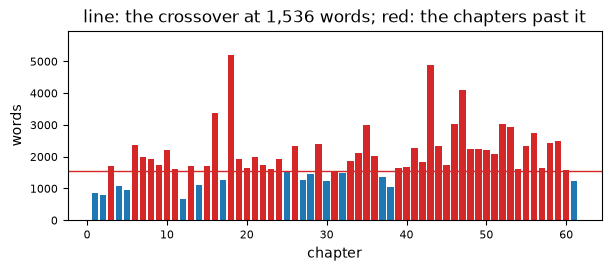

In [2]:
WIDTH = 768
lengths_chart(WIDTH)

### Solution

In [3]:
past = {w: int((lengths > 2 * w).sum()) for w in (768, 2048, 64)}
display(Markdown(f"The novel's {len(chapters)} chapters take {lengths.sum():,} steps in order and {int((lengths ** 2).sum()):,} "
                 "scores. Chapters past the crossover: " + ", ".join(f"{v} of {len(chapters)} at width {w:,}" for w, v in past.items())
                 + f". At GPT-2 small's width a whole chapter costs more in scores than in projections in {past[768]} of {len(chapters)}; its 1,024 positions hold {int((lengths <= GPT2['positions']).sum())} of the chapters whole."))

The novel's 61 chapters take 122,174 steps in order and 288,808,470 scores. Chapters past the crossover: 46 of 61 at width 768, 3 of 61 at width 2,048, 61 of 61 at width 64. At GPT-2 small's width a whole chapter costs more in scores than in projections in 46 of 61; its 1,024 positions hold 4 of the chapters whole.

## 2. One sentence, every pair

The setup gave each word of the novel a vector. Here the queries, the keys
and the values are all the words' own vectors, with no learned matrices. A
word with no vector scores 0 against every word, so its row gives each word
the same weight. Run the cell for the novel's first sentence: how much of its
weight does a word put on itself, with and without the division by √d, where
d is the number of entries in a word's vector, 100 here? Then set `CAUSAL` to
True.

no vector, zeros: universally
weight on the word itself and its copies, mean of 23 rows: 0.895 unscaled, 0.751 divided by √100; row sums 1.000 to 1.000


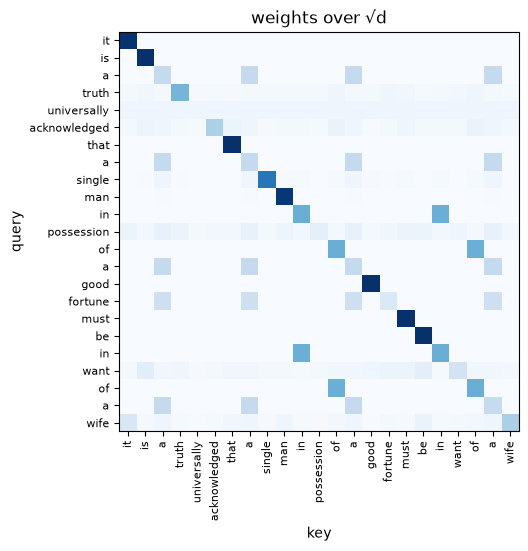

In [4]:
SENTENCE = FIRST
CAUSAL = False
attend(SENTENCE, CAUSAL)

### Solution

In [5]:
X = vectors(words := split(FIRST))
A0, A, f, a = weights(X, False), weights(X), words.index("fortune"), words.index("a")
display(Markdown(f"On average a word puts {own(A0, words):.3f} of its weight on itself and its copies without the division, {own(A, words):.3f} "
                 f"with it. A dot product grows with a vector's length, so `fortune`, of length {np.linalg.norm(X[f]):.1f}, puts {A0[f, f]:.3f} "
                 f"on itself and {A0[f, a]:.3f} on each `a`, of length {np.linalg.norm(X[a]):.1f}; learned matrices let a word read other words on "
                 f"purpose. With the mask a word puts {own(weights(X, False, True), words):.3f} on itself unscaled and "
                 f"{own(weights(X, True, True), words):.3f} scaled, more than without it, because it sees fewer words; the first word sees only itself."))

On average a word puts 0.895 of its weight on itself and its copies without the division, 0.751 with it. A dot product grows with a vector's length, so `fortune`, of length 8.8, puts 0.004 on itself and 0.249 on each `a`, of length 37.1; learned matrices let a word read other words on purpose. With the mask a word puts 0.909 on itself unscaled and 0.804 scaled, more than without it, because it sees fewer words; the first word sees only itself.

## 3. Words in another order

`SHIFT` rotates the sentence: every word moves that many places to the left,
and the first words go to the end. Run the cell: how much does any word's
output row change with no position signal, and how much once sinusoidal codes
are added to the vectors? A value printed with a large negative power of ten
after the e is zero up to the rounding of the arithmetic. Then try `SHIFT` 1
and a sentence of your own.

rotated: acknowledged that a single man in possession of a good fortune must be in want of a wife it is a truth universally
largest change in a word's output row: 5.3e-15 without positions, 9.456 with sinusoids, where the output rows with sinusoids have lengths 7.7 to 39.2


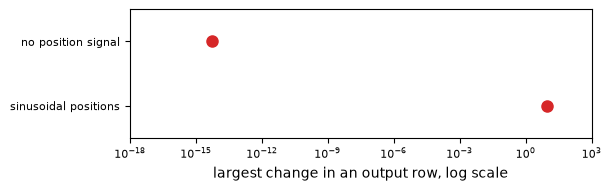

In [6]:
SENTENCE = FIRST
SHIFT = 5
shuffle(SENTENCE, SHIFT)

### Solution

In [7]:
found = {k: gaps(FIRST, k)[2:4] for k in dict.fromkeys([5, 1])}
display(Markdown("Largest change: " + "; ".join(f"{p:.1e} without positions and {c:.3f} with them at shift {k}" for k, (p, c) in found.items())
                 + ". Without a position signal the layer returns each word's row unchanged in its new place, for this "
                 "rotation and for any other order, up to the rounding of the arithmetic; with the codes added, a word's row depends on where it stands."))

Largest change: 5.3e-15 without positions and 9.456 with them at shift 5; 5.3e-15 without positions and 4.725 with them at shift 1. Without a position signal the layer returns each word's row unchanged in its new place, for this rotation and for any other order, up to the rounding of the arithmetic; with the codes added, a word's row depends on where it stands.

## Appendix. Where the parameters are

A GPT-2-shaped model of L blocks and width d holds 4d² attention weights and
8d² feed-forward weights per block, so L × 12d² in its blocks. Its token
table holds one row of d numbers per token and serves as the output layer
too, and its position table one row per position. Each block adds 13d biases
and layer-norm weights: 4d for the attention's biases, 5d for the
feed-forward network's and 4d for its two layer norms. The lecture's count for
one block leaves out the attention's 4d. The final layer norm adds 2d.

The chart compares GPT-2 small with the same model given the novel's
vocabulary, one token per different word.

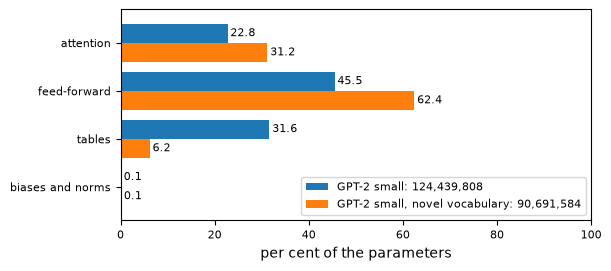

In [8]:
split_chart(models)

**Exercise.** Keep the novel's vocabulary and set `WIDTH_A` and `LAYERS` to
a smaller model, such as width 256 with 6 blocks. Which part holds the
largest share now?

In [9]:
WIDTH_A, LAYERS = 768, 12

if type(WIDTH_A) is not int or type(LAYERS) is not int or not (1 <= WIDTH_A <= 8192 and 1 <= LAYERS <= 96):
    raise Refused(f"WIDTH_A is {WIDTH_A!r} and LAYERS {LAYERS!r}: WIDTH_A takes 1 to 8192, LAYERS 1 to 96, whole numbers.")
mine = parts(LAYERS, WIDTH_A, GPT2["positions"], len(counts))
print(", ".join(f"{k} {v:,} ({100 * v / sum(mine.values()):.1f} per cent)" for k, v in mine.items()))

attention 28,311,552 (31.2 per cent), feed-forward 56,623,104 (62.4 per cent), tables 5,635,584 (6.2 per cent), biases and norms 121,344 (0.1 per cent)


### Solution

In [10]:
share, small = (lambda p, k: 100 * p[k] / sum(p.values())), parts(6, 256, GPT2["positions"], len(counts))
display(Markdown(f"GPT-2 small keeps {share(models['GPT-2 small'], 'feed-forward'):.1f} per cent in its feed-forward networks and "
                 f"{share(models['GPT-2 small'], 'tables'):.1f} in its tables. With the novel's {len(counts):,} words the tables "
                 f"fall to {share(models['GPT-2 small, novel vocabulary'], 'tables'):.1f}. At width 256 with 6 blocks the feed-forward networks "
                 f"still hold the largest share, {share(small, 'feed-forward'):.1f} per cent, the tables {share(small, 'tables'):.1f} and "
                 f"attention {share(small, 'attention'):.1f}: block weights grow with the square of the width and the tables with the width."))

GPT-2 small keeps 45.5 per cent in its feed-forward networks and 31.6 in its tables. With the novel's 6,314 words the tables fall to 6.2. At width 256 with 6 blocks the feed-forward networks still hold the largest share, 47.5 per cent, the tables 28.4 and attention 23.8: block weights grow with the square of the width and the tables with the width.